# EDA: Amazon fashion sample

In [1]:
# Work from the repo root, so `similarity` imports and the data/ paths resolve when opened from notebooks/
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

path = Path("data/archive/marketing_sample_for_amazon_com-amazon_fashion_products__20200201_20200430__30k_data.ldjson")
df = pd.read_json(path, lines=True)
df.shape

(30000, 33)

In [3]:
df.columns.tolist()

['uniq_id',
 'crawl_timestamp',
 'asin',
 'product_url',
 'product_name',
 'image_urls__small',
 'medium',
 'large',
 'browsenode',
 'brand',
 'sales_price',
 'weight',
 'rating',
 'sales_rank_in_parent_category',
 'sales_rank_in_child_category',
 'delivery_type',
 'meta_keywords',
 'amazon_prime__y_or_n',
 'parent___child_category__all',
 'best_seller_tag__y_or_n',
 'other_items_customers_buy',
 'product_details__k_v_pairs',
 'discount_percentage',
 'colour',
 'no__of_reviews',
 'seller_name',
 'seller_id',
 'left_in_stock',
 'no__of_offers',
 'no__of_sellers',
 'technical_details__k_v_pairs',
 'formats___editions',
 'name_of_author_for_books']

In [4]:
df.dtypes

uniq_id                           object
crawl_timestamp                   object
asin                              object
product_url                       object
product_name                      object
image_urls__small                 object
medium                            object
large                             object
browsenode                       float64
brand                             object
sales_price                      float64
weight                            object
rating                           float64
sales_rank_in_parent_category     object
sales_rank_in_child_category      object
delivery_type                     object
meta_keywords                     object
amazon_prime__y_or_n              object
parent___child_category__all      object
best_seller_tag__y_or_n           object
other_items_customers_buy         object
product_details__k_v_pairs        object
discount_percentage               object
colour                            object
no__of_reviews  

In [5]:
df.head()

,uniq_id,crawl_timestamp,asin,product_url,product_name,image_urls__small,medium,large,browsenode,brand,...,colour,no__of_reviews,seller_name,seller_id,left_in_stock,no__of_offers,no__of_sellers,technical_details__k_v_pairs,formats___editions,name_of_author_for_books
0,26d41bdc1495de290bc8e6062d927729,2020-02-07 05:11:36 +0000,B07STS2W9T,https://www.amazon.in/Facon-Kalamkari-Handbloc...,LA' Facon Cotton Kalamkari Handblock Saree Blo...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,1.968255e+09,LA' Facon,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,410c62298852e68f34c35560f2311e5a,2020-02-07 08:45:56 +0000,B07N6TD2WL,https://www.amazon.in/Sf-Jeans-Pantaloons-T-Sh...,Sf Jeans By Pantaloons Men's Plain Slim fit T-...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,1.968123e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,52e31bb31680b0ec73de0d781a23cc0a,2020-02-06 11:09:38 +0000,B07WJ6WPN1,https://www.amazon.in/LOVISTA-Traditional-Prin...,LOVISTA Cotton Gota Patti Tassel Traditional P...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,1.968255e+09,LOVISTA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,25798d6dc43239c118452d1bee0fb088,2020-02-07 08:32:45 +0000,B07PYSF4WZ,https://www.amazon.in/People-Printed-Regular-T...,People Men's Printed Regular fit T-Shirt,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,1.968123e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ad8a5a196d515ef09dfdaf082bdc37c4,2020-02-06 14:27:48 +0000,B082KXNM7X,https://www.amazon.in/Monte-Carlo-Cotton-Colla...,Monte Carlo Grey Solid Cotton Blend Polo Colla...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,https://images-na.ssl-images-amazon.com/images...,1.968070e+09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.iloc[0].to_dict()

{'uniq_id': '26d41bdc1495de290bc8e6062d927729',
 'crawl_timestamp': '2020-02-07 05:11:36 +0000',
 'asin': 'B07STS2W9T',
 'product_url': 'https://www.amazon.in/Facon-Kalamkari-Handblock-Dancers-Lehenga/dp/B07SWVSRPP/',
 'product_name': "LA' Facon Cotton Kalamkari Handblock Saree Blouse Fabric 100 cms Black Base Dancers (Cotton)",
 'image_urls__small': 'https://images-na.ssl-images-amazon.com/images/I/51Wj2WownyL._SR38,50_.jpg|https://images-na.ssl-images-amazon.com/images/I/51tylkSxAIL._SR38,50_.jpg|https://images-na.ssl-images-amazon.com/images/I/51345gshQ9L._SR38,50_.jpg',
 'medium': 'https://images-na.ssl-images-amazon.com/images/I/51Wj2WownyL.jpg|https://images-na.ssl-images-amazon.com/images/I/51tylkSxAIL.jpg|https://images-na.ssl-images-amazon.com/images/I/51345gshQ9L.jpg',
 'large': 'https://images-na.ssl-images-amazon.com/images/I/81MqmouZ9kL._UL1500_.jpg|https://images-na.ssl-images-amazon.com/images/I/814Tnuvt5kL._UL1500_.jpg|https://images-na.ssl-images-amazon.com/images/I/81

In [7]:
df.isna().sum().sort_values(ascending=False)

name_of_author_for_books         29999
formats___editions               29998
no__of_offers                    28980
no__of_sellers                   28980
technical_details__k_v_pairs     28846
left_in_stock                    26943
no__of_reviews                   26548
colour                           23971
seller_id                        21636
seller_name                      21636
discount_percentage              15376
brand                             8143
other_items_customers_buy         5637
sales_rank_in_child_category      5149
sales_rank_in_parent_category     4503
parent___child_category__all      4503
sales_price                       2890
product_details__k_v_pairs        1183
large                             1159
browsenode                         520
medium                               2
image_urls__small                    2
uniq_id                              0
asin                                 0
crawl_timestamp                      0
meta_keywords            

In [8]:
print("uniq_id", df["uniq_id"].nunique())
print("asin", df["asin"].nunique())
print("product_name", df["product_name"].nunique())
df["product_name"].duplicated().sum()

uniq_id 30000
asin 29529
product_name 22424


np.int64(7576)

## sales_price

In [9]:
df["sales_price"].head(15)

0      200.0
1      265.0
2      660.0
3      195.0
4     1914.0
5      350.0
6      288.0
7      919.0
8        NaN
9      619.0
10       NaN
11     289.0
12     462.0
13     499.0
14     329.0
Name: sales_price, dtype: float64

In [10]:
df["sales_price"].value_counts(dropna=False).head(15)

sales_price
NaN      2890
399.0    1041
299.0     912
599.0     893
499.0     615
349.0     601
799.0     573
699.0     504
999.0     481
899.0     445
449.0     426
549.0     424
749.0     313
199.0     297
249.0     273
Name: count, dtype: int64

In [11]:
price = pd.to_numeric(df["sales_price"], errors="coerce")
price.describe()

count    27110.000000
mean       862.172397
std        964.223008
min         39.000000
25%        379.000000
50%        590.000000
75%        899.000000
max       9988.000000
Name: sales_price, dtype: float64

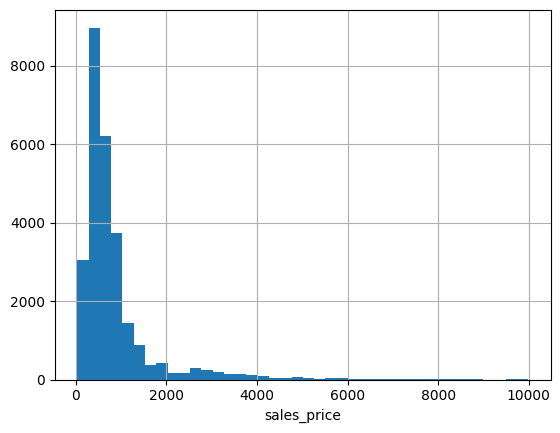

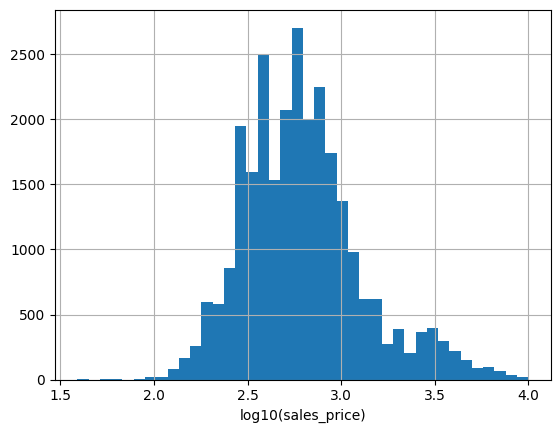

In [12]:
price.hist(bins=40)
plt.xlabel("sales_price")
plt.show()

np.log10(price[price > 0]).hist(bins=40)
plt.xlabel("log10(sales_price)")
plt.show()

## rating

In [13]:
df["rating"].head(10)

0    5.0
1    3.6
2    3.5
3    3.0
4    5.0
5    4.1
6    3.7
7    2.9
8    4.4
9    5.0
Name: rating, dtype: float64

In [14]:
pd.to_numeric(df["rating"], errors="coerce").value_counts(dropna=False).sort_index()

rating
1.0     588
1.3       3
1.4       2
1.5      21
1.6       3
1.7       2
1.8       7
1.9      12
2.0     307
2.1      26
2.2      18
2.3      31
2.4      54
2.5     145
2.6      94
2.7     110
2.8     139
2.9     241
3.0    1802
3.1     465
3.2     647
3.3     791
3.4     940
3.5    1140
3.6     998
3.7    1041
3.8    1068
3.9    1142
4.0    3861
4.1     936
4.2     897
4.3     887
4.4     844
4.5    1403
4.6     879
4.7     651
4.8     289
4.9      66
5.0    7450
Name: count, dtype: int64

## weight

In [15]:
df["weight"].head(15)

0     999999999
1     999999999
2     999999999
3     999999999
4     999999999
5     999999999
6        99.8 g
7     999999999
8     999999999
9     999999999
10    999999999
11    999999999
12        240 g
13        249 g
14    999999999
Name: weight, dtype: object

In [16]:
df["weight"].value_counts(dropna=False).head(20)

weight
999999999    23745
200 g          736
249 g          689
299 g          398
399 g          304
349 g          259
99.8 g         251
449 g          228
150 g          190
499 g          168
181 g          163
272 g          117
68 g           115
113 g          113
90.7 g         108
222 g           97
86.2 g          94
227 g           80
59 g            80
281 g           66
Name: count, dtype: int64

## brand

In [17]:
df["brand"].head(15)

0           LA' Facon
1                 NaN
2             LOVISTA
3                 NaN
4                 NaN
5         Forest Club
6        PrintOctopus
7                 NaN
8            Carahere
9          Peppermint
10    Haase Unlimited
11                NaN
12        Jevi Prints
13               OLLI
14                NaN
Name: brand, dtype: object

In [18]:
df["brand"].value_counts(dropna=False).head(20)

brand
NaN                       8143
Max                        504
Generic                    245
BIBA                       205
Mothercare                 156
Campus Sutra               150
Soch                       149
nauti nati                 132
Ada                        127
GRITSTONES                 110
PrintOctopus               102
Allen Solly Junior          93
Columbia                    92
Excalibur by Unlimited      80
Indian Terrain              80
ANNI DESIGNER               78
Buckle Down                 78
MIMOSA                      76
Gini & Jony                 69
Arrow Sports                68
Name: count, dtype: int64

In [19]:
df["brand"].nunique(dropna=True)

6458

## colour

In [20]:
df["colour"].dropna().head(20)

5                                       Black|Blue|Grey
6                                       Black|Navy Blue
15                                         Black|Maroon
20    Black Based|Black Based 2|Black White|Blue Whi...
22    Black|Bottle green|GREEN|NAVY BLUE|Pink|Red|WH...
23                                          Black|White
29                                           Black|Blue
33                                    Black|Pink|Yellow
34                                       Green|Pink|Red
36    Black Half|Black Sando|Rust|Black Full|Maroon|...
37    Argos - Black|Devon - Black|Ethan - Blue|Grand...
41                               Baroque Rose|Marmalade
51    WHITE|NAVY BLUE|RANI|BLACK|MEHROON|SKIN|SKIN/G...
53               BLUE|NAVY|OLIVE|Orange|RANI|STRAWBERRY
57                Light green|Navy blue|Orange|Pink|Red
61                                            Beige|Red
65    Black|Green|Navy Blue|Grey|Maroon|White|Black ...
72    Black and Potent Purple|Blue Melange and G

In [21]:
df["colour"].value_counts(dropna=False).head(20)

colour
NaN                23971
Black|White           79
Black|Blue            45
Black|Red             34
Black|Navy            31
Blue|Red              30
Black|Navy Blue       21
Black|Grey            21
Blue|Pink             21
White|Black           20
White|Yellow          19
Black|Blue|Red        18
Green|Red             17
Brown|Black           15
Blue|Yellow           15
Blue|Grey             15
Pink|Red              15
Red|Yellow            14
Black|Maroon          12
Black|Pink            12
Name: count, dtype: int64

In [22]:
df["colour"].dropna().str.split("|").map(len).value_counts().sort_index()

colour
2     1933
3     1097
4      791
5      552
6      411
7      294
8      189
9      143
10     114
11      69
12      56
13      65
14      38
15      49
16      30
17      20
18      23
19      20
20      16
21      15
22      14
23       8
24       9
25      10
26       7
27       6
28       3
29       3
30       3
31       4
32       5
33       1
34       4
35       4
36       4
37       1
39       2
40       2
41       2
42       1
43       2
44       3
45       1
47       1
51       1
80       3
Name: count, dtype: int64

## category

In [23]:
df["browsenode"].head(10)

0    1.968255e+09
1    1.968123e+09
2    1.968255e+09
3    1.968123e+09
4    1.968070e+09
5    1.968097e+09
6    1.968123e+09
7    1.968094e+09
8    1.968058e+09
9    1.596695e+10
Name: browsenode, dtype: float64

In [24]:
df["browsenode"].nunique(dropna=True)

302

In [25]:
df["sales_rank_in_child_category"].dropna().head(8)

0    {'WomensKurtasKurtis': '#1793'}
1         {'MensT_Shirts': '#12151'}
2      {'WomensKurtasKurtis': '#91'}
3         {'MensT_Shirts': '#19368'}
4          {'MensTracksuits': '#12'}
5              {'MensShorts': '#30'}
6           {'MensT_Shirts': '#817'}
7     {'MensCasualShirts': '#43603'}
Name: sales_rank_in_child_category, dtype: object

In [26]:
df["sales_rank_in_parent_category"].dropna().head(8)

0      {'ClothingAccessories': '#19,259'}
1    {'ClothingAccessories': '#1,59,062'}
2       {'ClothingAccessories': '#1,050'}
3    {'ClothingAccessories': '#2,47,234'}
4      {'ClothingAccessories': '#13,980'}
5       {'ClothingAccessories': '#4,399'}
6      {'ClothingAccessories': '#14,838'}
7    {'ClothingAccessories': '#7,97,407'}
Name: sales_rank_in_parent_category, dtype: object

In [27]:
df["sales_rank_in_child_category"].map(
    lambda value: next(iter(value)) if isinstance(value, dict) and value else np.nan
).value_counts().head(15)

sales_rank_in_child_category
WomensKurtasKurtis              3534
MensT_Shirts                    3385
WomensSarees                    1808
MensFormalShirts                1060
GirlsDressesJumpsuits            992
MensCasualShirts                 866
BoysT_Shirts                     856
WomensDresses                    759
WomensEthnicUnstitchedFabric     664
WomensBlousesShirts              574
GirlsT_Shirts                    553
WomensTops                       542
MensUnderwearBriefs              507
WomensT_Shirts                   505
WomensChuridarSalwarBottoms      500
Name: count, dtype: int64

In [28]:
df["sales_rank_in_parent_category"].map(
    lambda value: next(iter(value)) if isinstance(value, dict) and value else np.nan
).value_counts().head(10)

sales_rank_in_parent_category
ClothingAccessories      24893
SportsFitnessOutdoors      374
BabyProducts                89
HomeKitchen                 23
AmazonLaunchpad             20
HealthPersonalCare          18
BagsWalletsandLuggage       18
CarMotorbike                16
ToysGames                   14
Electronics                 10
Name: count, dtype: int64

## name and images

In [29]:
df["product_name"].head(10)

0    LA' Facon Cotton Kalamkari Handblock Saree Blo...
1    Sf Jeans By Pantaloons Men's Plain Slim fit T-...
2    LOVISTA Cotton Gota Patti Tassel Traditional P...
3             People Men's Printed Regular fit T-Shirt
4    Monte Carlo Grey Solid Cotton Blend Polo Colla...
5    Forest Club | Gym Wear | Sports Shorts| Shorts...
6    PrintOctopus Graphic Printed T-Shirt for Men C...
7      Pepe Jeans Men's Solid Regular fit Casual Shirt
8    Carahere Boys Handmade Pre-Tied Classic Polka ...
9                           Peppermint Synthetic Dress
Name: product_name, dtype: object

In [30]:
df["product_name"].str.len().describe()

count    30000.000000
mean        57.901067
std         31.918000
min          4.000000
25%         37.000000
50%         50.000000
75%         72.000000
max        500.000000
Name: product_name, dtype: float64

In [31]:
df["medium"].dropna().head(5)

0    https://images-na.ssl-images-amazon.com/images...
1    https://images-na.ssl-images-amazon.com/images...
2    https://images-na.ssl-images-amazon.com/images...
3    https://images-na.ssl-images-amazon.com/images...
4    https://images-na.ssl-images-amazon.com/images...
Name: medium, dtype: object

In [32]:
df[["image_urls__small", "medium", "large"]].isna().sum()

image_urls__small       2
medium                  2
large                1159
dtype: int64

## other columns

In [33]:
df["discount_percentage"].value_counts(dropna=False).head(15)

discount_percentage
NaN    15376
50%     1677
60%      951
20%      948
55%      583
40%      577
70%      498
65%      393
75%      284
45%      259
30%      253
67%      232
61%      232
57%      232
63%      230
Name: count, dtype: int64

In [34]:
df["amazon_prime__y_or_n"].value_counts(dropna=False)

amazon_prime__y_or_n
N    16500
Y    13500
Name: count, dtype: int64

In [35]:
df["best_seller_tag__y_or_n"].value_counts(dropna=False)

best_seller_tag__y_or_n
N    29987
Y       13
Name: count, dtype: int64

In [36]:
df["delivery_type"].value_counts(dropna=False)

delivery_type
fulfilled_by_merchant    26382
fulfilled_by_amazon       3618
Name: count, dtype: int64